In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from sklearn.covariance import ledoit_wolf
from pathlib import Path
from jcamp import readfile
import locale
import pickle
import yaml

In [2]:
from setup import (
    violet,
    blue,
    green,
    yellow,
    orange,
    red,
    white,
    gray,
    black,
    colors,
    plot_style,
    filepath,
    configuration,
    training_labels,
    spectral_range,
    training_settling_time as settling_time,
    calibration_type,
    predictor_type,
)
from processing import (
    is_system_settled,
    broaden_spectrum,
    scaling_from_pid_to_cell,
    cm2inch,
)

In [3]:
locale.setlocale(locale.LC_ALL, "en_US.UTF-8")

plt.style.use(plot_style)
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 0.7,
        "patch.linewidth": 0.7,
        "lines.markeredgewidth": 0.7,
        "lines.markersize": 3.5,
        "axes.formatter.use_locale": True,
    }
)

### Load training datasets

In [4]:
times = []
voltages = []
absorbances = []
flowrates = []
setpoints = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

if predictor_type != "absorbance":
    raise ValueError(f"Unsupported predictor type: {predictor_type}.")

for label in training_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    flowrate_0 = dataset["flowrate_0"]
    flowrate_1 = dataset["flowrate_1"]
    flowrate_2 = dataset["flowrate_2"]
    flowrate = np.stack(
        [
            np.mean(flowrate_0, axis=1),
            np.mean(flowrate_1, axis=1),
            np.mean(flowrate_2, axis=1),
        ],
        axis=1,
    )

    voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
    voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
    voltage = np.stack(
        [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    spectrum = spectrum[:, spectral_mask]

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))

    times.append(time)
    voltages.append(voltage)
    absorbances.append(absorbance)
    flowrates.append(flowrate)
    setpoints.append(setpoint)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
voltages = np.concatenate(voltages, axis=0)
absorbances = np.concatenate(absorbances, axis=0)
flowrates = np.concatenate(flowrates, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)
wavenumber = wavenumber[spectral_mask]

In [5]:
number_spectra, number_wavenumbers = np.shape(absorbances)
number_gases = len(gases)
gas_pair = "-".join(gas.lower() for gas in gases)
gas_labels = {"isopropanol": "iPrOH", "ethanol": "EtOH"}

print(f"Datasets: {', '.join(training_labels)}")
print(f"Gases: {gas_labels[gas_1]}, {gas_labels[gas_2]}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_71F
Gases: iPrOH, EtOH
Spectra: 882 (402 are settled, 210 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


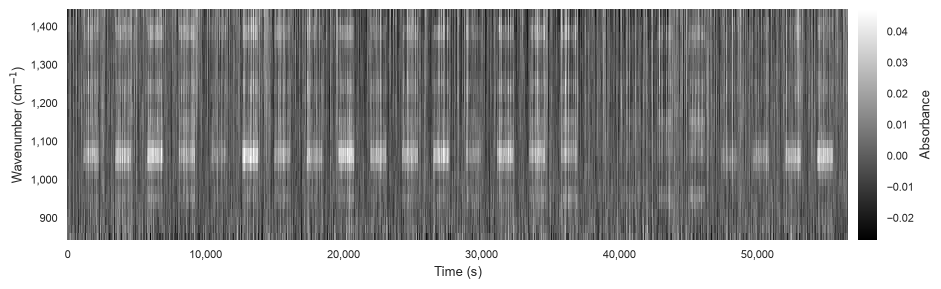

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber,
    absorbances.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label="Absorbance", aspect=12, pad=0.01)

### Load calibrated concentrations

In [7]:
concentrations = []
cutoff_concentrations = []
scalings_pid_to_cell = []
for ii, gas in enumerate(gases):
    with open(Path("models", f"estimator-{gas.lower()}.pkl"), "rb") as file:
        calibration = pickle.load(file)

    concentration_estimator = calibration["estimator"]

    if calibration_type == "flowrate":
        concentration = concentration_estimator(flowrates[:, ii + 1])
    elif calibration_type == "pid":
        scaling_pid_to_cell = scaling_from_pid_to_cell(flowrates, split_ratio, ii + 1)
        concentration = scaling_pid_to_cell * concentration_estimator(voltages[:, ii])

        cutoff_concentrations.append(calibration["cutoff_concentration"])
        scalings_pid_to_cell.append(scaling_pid_to_cell)

    concentrations.append(concentration)

concentrations = np.stack(concentrations, axis=1)
if calibration_type == "pid":
    cutoff_concentrations = np.array(cutoff_concentrations)
    scalings_pid_to_cell = np.stack(scalings_pid_to_cell, axis=1)

### Define selection mask

In [8]:
selection_mask = are_settled
if calibration_type == "pid":
    selection_mask = selection_mask & np.all(
        concentrations < cutoff_concentrations * scalings_pid_to_cell,
        axis=1,
    )

### Load reference spectra

In [9]:
wavenumber_nist = {}
absorption_coefficients_nist = {}
for gas in gases:
    data_nist = readfile(Path("NIST", f"{gas}.jdx"))

    if data_nist["yunits"] == "TRANSMITTANCE":
        data_nist["y"] = -np.log10(data_nist["y"])

    wavenumber_nist[gas] = data_nist["x"]
    absorption_coefficients_nist[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution,
        window_type,
    )

    spectral_mask_nist = (wavenumber_nist[gas] >= spectral_range[0]) & (
        wavenumber_nist[gas] <= spectral_range[1]
    )
    wavenumber_nist[gas] = wavenumber_nist[gas][spectral_mask_nist]
    absorption_coefficients_nist[gas] = absorption_coefficients_nist[gas][
        spectral_mask_nist
    ]

### Load regression model

In [10]:
with open(Path("models", f"ridge-{gas_pair}.pkl"), "rb") as file:
    model = pickle.load(file)

model_weights = model.named_steps["model"].coef_.T

concentration_predictions = model.predict(absorbances)

### Filter model predictions

In [11]:
with open(Path("models", f"kalman-{gas_pair}.pkl"), "rb") as file:
    kalman_filter = pickle.load(file)

In [12]:
concentrations_filtered = np.zeros_like(concentration_predictions)

for ii in range(number_spectra):
    kalman_filter.predict()
    kalman_filter.update(concentration_predictions[ii, :])

    concentrations_filtered[ii, :] = kalman_filter.x

### Plot training characterization

In [13]:
c_min = np.min((concentrations_filtered.min(), concentrations.min()))
c_max = np.max((concentrations_filtered.max(), concentrations.max()))

r_max = np.max(np.abs(concentrations_filtered - concentrations))
r_min = -r_max

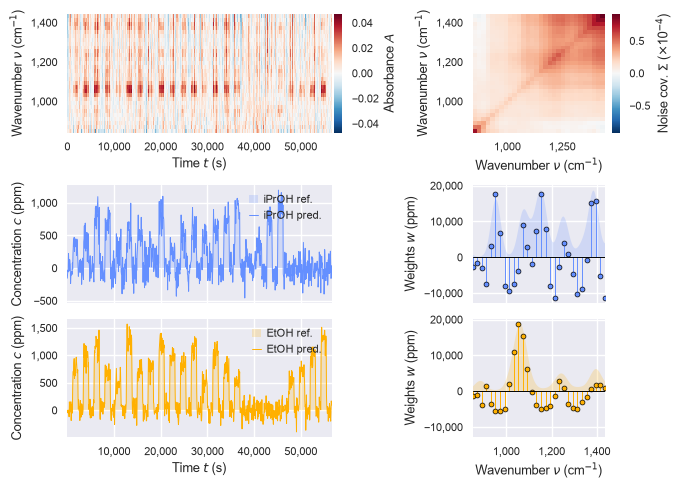

In [14]:
fig, axs = plt.subplots(
    3,
    2,
    figsize=cm2inch((17, 12)),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [2, 1]},
)

### spectro-temporal absorbance spectrum ###
absorbance_absolute_maximum = np.max(np.abs(absorbances))
mesh = axs[0, 0].pcolormesh(
    times,
    wavenumber,
    absorbances.T,
    cmap="RdBu_r",
    vmin=-absorbance_absolute_maximum,
    vmax=absorbance_absolute_maximum,
    rasterized=True,
)

fig.colorbar(mesh, ax=axs[0, 0], label="Absorbance $A$", aspect=15, pad=0.01)

axs[0, 0].set_xlabel("Time $t$ (s)")
axs[0, 0].set_ylabel("Wavenumber $\\nu$ (cm$^{-1}$)")
axs[0, 0].margins(0, 0.05)

### isopropanol reference concentrations and predictions ###
axs[1, 0].fill_between(
    times,
    concentrations[:, 0],
    facecolor=blue + "33",
    label="iPrOH ref.",
    zorder=5,
)
axs[1, 0].plot(
    times,
    concentrations_filtered[:, 0],
    color=blue,
    label="iPrOH pred.",
    zorder=10,
)

axs[1, 0].set_xticklabels([])
axs[1, 0].set_ylabel("Concentration $c$ (ppm)")
axs[1, 0].margins(0, 0.05)
legend = axs[1, 0].legend(handlelength=0.8, handletextpad=0.5, loc="upper right")
legend.set_zorder(20)

### ethanol reference concentrations and predictions ###
axs[2, 0].fill_between(
    times,
    concentrations[:, 1],
    facecolor=yellow + "33",
    label="EtOH ref.",
    zorder=5,
)
axs[2, 0].plot(
    times,
    concentrations_filtered[:, 1],
    color=yellow,
    label="EtOH pred.",
    zorder=10,
)

axs[2, 0].set_xlabel("Time $t$ (s)")
axs[2, 0].set_ylabel("Concentration $c$ (ppm)")
axs[2, 0].margins(0, 0.05)
legend = axs[2, 0].legend(handlelength=0.8, handletextpad=0.5, loc="upper right")
legend.set_zorder(20)

### covariances ###
noise_covariance, _ = ledoit_wolf(absorbances[are_analyte_free, :])

absolute_maximum_value = 1e4 * np.max(np.abs(noise_covariance))

mesh = axs[0, 1].pcolormesh(
    wavenumber,
    wavenumber,
    1e4 * noise_covariance,
    vmin=-absolute_maximum_value,
    vmax=absolute_maximum_value,
    cmap="RdBu_r",
    rasterized=True,
)

fig.colorbar(
    mesh,
    ax=axs[0, 1],
    label="Noise cov. $\\Sigma$ ($\\times$10$^{-4}$)",
    aspect=15,
    pad=0.01,
)

axs[0, 1].set_xlabel("Wavenumber $\\nu$ (cm$^{-1}$)")
axs[0, 1].set_ylabel("Wavenumber $\\nu$ (cm$^{-1}$)")

### isopropanol weights ###
markerline, stemlines, baseline = axs[1, 1].stem(
    wavenumber,
    model_weights[:, 0],
)
plt.setp(stemlines, color=blue, zorder=10)
plt.setp(
    markerline,
    markerfacecolor=blue,
    markeredgecolor=black,
    marker="o",
    markeredgewidth=0.5,
    zorder=15,
)
plt.setp(baseline, color=black, zorder=15)

axs[1, 1].fill_between(
    wavenumber_nist["isopropanol"],
    np.max(model_weights)
    * absorption_coefficients_nist["isopropanol"]
    / np.max(absorption_coefficients_nist["isopropanol"]),
    facecolor=blue + "33",
    zorder=5,
)

axs[1, 1].set_xticklabels([])
axs[1, 1].set_ylabel("Weights $w$ (ppm)")
axs[1, 1].set_xlim(np.min(wavenumber), np.max(wavenumber))
axs[1, 1].margins(0, 0.05)

### ethanol weights ###
markerline, stemlines, baseline = axs[2, 1].stem(
    wavenumber,
    model_weights[:, 1],
)
plt.setp(stemlines, color=yellow, zorder=10)
plt.setp(
    markerline,
    markerfacecolor=yellow,
    markeredgecolor=black,
    marker="o",
    markeredgewidth=0.5,
    zorder=15,
)
plt.setp(baseline, color=black, zorder=15)

axs[2, 1].fill_between(
    wavenumber_nist["ethanol"],
    np.max(model_weights)
    * absorption_coefficients_nist["ethanol"]
    / np.max(absorption_coefficients_nist["ethanol"]),
    facecolor=yellow + "33",
    zorder=5,
)

axs[2, 1].set_xlabel("Wavenumber $\\nu$ (cm$^{-1}$)")
axs[2, 1].set_ylabel("Weights $w$ (ppm)")
axs[2, 1].set_xlim(np.min(wavenumber), np.max(wavenumber))
axs[2, 1].sharey(axs[1, 1])
axs[2, 1].margins(0, 0.05)

filepath = Path("..", "Figures", f"s03-training-characterization-{configuration}.svg")
fig.savefig(filepath, dpi=600)